## Most frequent place per monarch

Counts how often each place from `holinshed_places.csv` (confidence ≥ 0.75) occurs in each `regnal_entry` of `monarchs_reign.xml`, then shows the top place per reign.

Margin notes (mostly source citations like "Math. Paris") and titles like "Duke of Yorke" are removed before counting.

Counting lives in `name_extraction/count_places.py`, shared with `places_per_reign.ipynb`. Spellings are matched by a normalized key (`VVestmynster` = `Westminster`, `Normãdye` = `Normandie`, `Oxforde` = `Oxford`), and one-word names must start with a capital letter so common words like "seeme" or "mercy" are not counted as places.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../name_extraction")
from count_places import load_texts, load_places, count_names

In [2]:
texts = load_texts("../1577_files/monarchs_reign.xml")
places = load_places("../name_extraction/entity_names/holinshed_places.csv")
# Old spellings of one place are summed (name_extraction/entity_names/place_aliases.csv)
counts = count_names(places, texts, strip_titles=True)  # rows: places, columns: monarchs (in text order)
counts.shape

(844, 23)

In [3]:
top = pd.DataFrame({"place": counts.idxmax(), "occurrences": counts.max()})
top

,place,occurrences
WilliamConqueror,York,21
WilliamRufus,Normandy,29
Henry I,Normandy,49
Stephen,Normandy,22
Henry II,Normandy,76
Richard I,York,36
John,London,54
Henry III,London,166
Edward I,Scotland,132
EdwardII,London,36


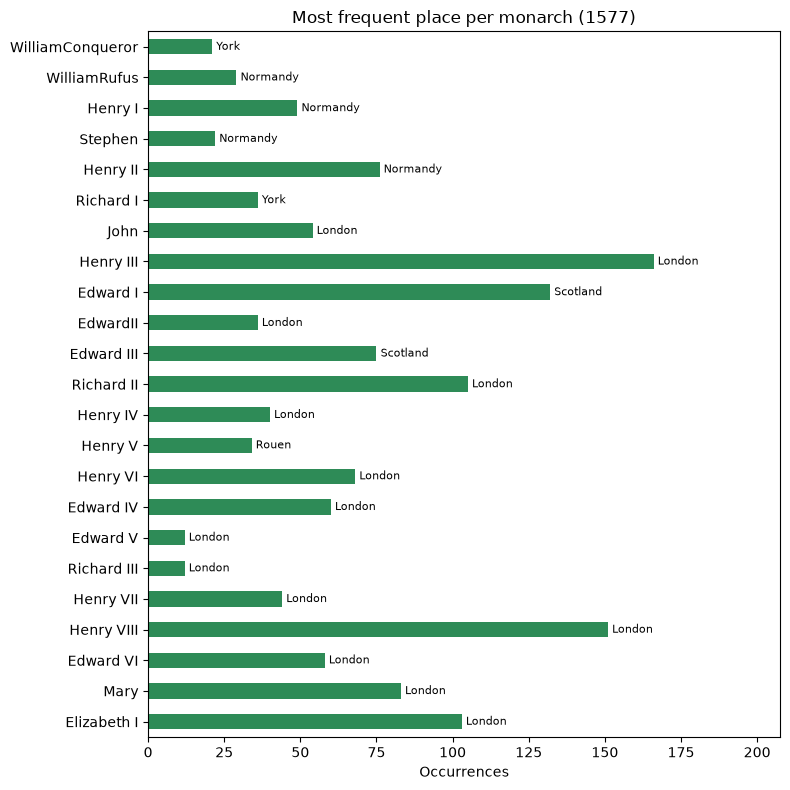

In [4]:
ax = top["occurrences"].plot.barh(figsize=(8, 8), color="seagreen")
ax.invert_yaxis()
ax.bar_label(ax.containers[0], labels=top["place"], padding=3, fontsize=8)
ax.set(title="Most frequent place per monarch (1577)", xlabel="Occurrences", ylabel="")
ax.set_xlim(0, top["occurrences"].max() * 1.25)
plt.tight_layout()
plt.show()

## Top places across reigns

The 8 places with the most mentions overall, tracked reign by reign.

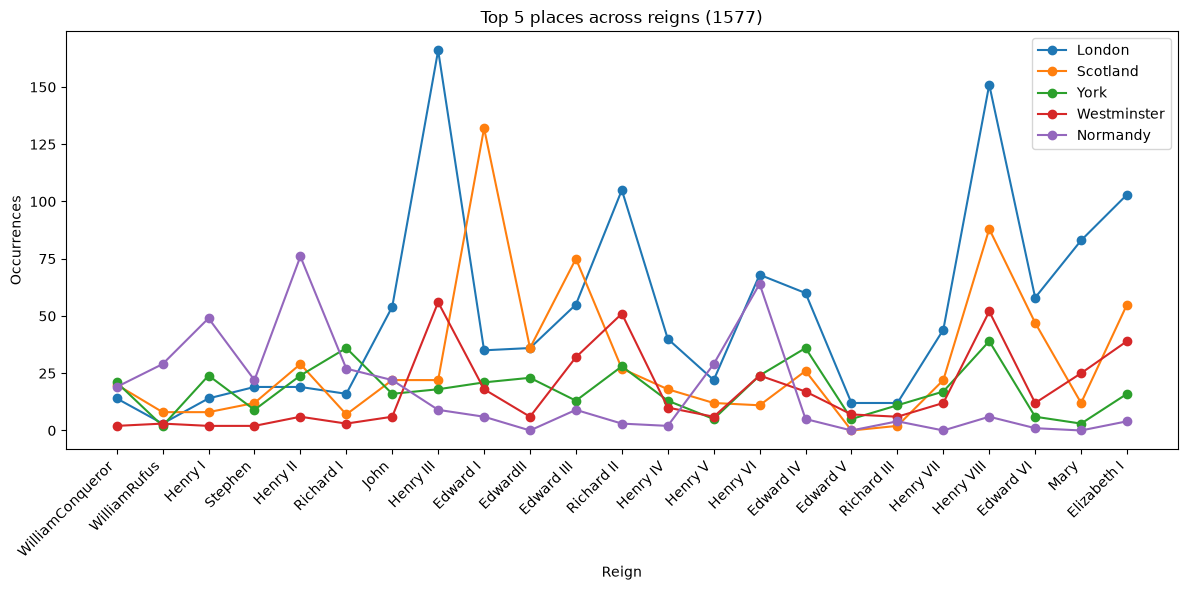

In [5]:
top_places = counts.sum(axis=1).nlargest(5).index
ax = counts.loc[top_places].T.plot(figsize=(12, 6), marker="o")
ax.set(title="Top 5 places across reigns (1577)", xlabel="Reign", ylabel="Occurrences")
ax.set_xticks(range(len(counts.columns)), counts.columns, rotation=45, ha="right")
plt.tight_layout()
plt.show()